# IPM rim and radial-profile analysis from astrodendro outputs

Run this notebook **after** your `astrodendro.ipynb` has saved its checkpoint to `./results`.

It uses your saved products:

- `first_pass_catalog.pkl`
- `labels_data.fits`
- `detection.fits`
- `ha.fits`, `hb.fits`, `oiii.fits`, `nii.fits`, `sii.fits`
- matching error maps
- `metadata.json`

It **does not recompute the background**. It reuses your astrodendro per-region values such as `ha_bg_level`, `oiii_bg_level`, and `sii_bg_level`, then subtracts those levels from the image cutouts.

The ionisation parameter map used here is:

$$\mathrm{IPM} = \log_{10}([\mathrm{SII}]/[\mathrm{OIII}])$$

Low IPM means high-ionisation core. High IPM means low-ionisation rim/front.

In [23]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter

pd.set_option("display.max_columns", 200)

## 1. Load your astrodendro checkpoint

In [24]:
checkpoint_dir = Path("./results")

cat2 = pd.read_pickle(checkpoint_dir / "first_pass_catalog.pkl")
labels_data = fits.getdata(checkpoint_dir / "labels_data.fits").astype(np.int32)
detection = fits.getdata(checkpoint_dir / "detection.fits")

pn_mask_path = checkpoint_dir / "pn_mask.fits"
pn_mask = fits.getdata(pn_mask_path).astype(bool) if pn_mask_path.exists() else np.zeros_like(labels_data, dtype=bool)

ha = fits.getdata(checkpoint_dir / "ha.fits")
ha_err = fits.getdata(checkpoint_dir / "ha_err.fits")

hb = fits.getdata(checkpoint_dir / "hb.fits")
hb_err = fits.getdata(checkpoint_dir / "hb_err.fits")

oiii = fits.getdata(checkpoint_dir / "oiii.fits")
oiii_err = fits.getdata(checkpoint_dir / "oiii_err.fits")

nii = fits.getdata(checkpoint_dir / "nii.fits")
nii_err = fits.getdata(checkpoint_dir / "nii_err.fits")

sii = fits.getdata(checkpoint_dir / "sii.fits")
sii_err = fits.getdata(checkpoint_dir / "sii_err.fits")

with open(checkpoint_dir / "metadata.json") as f:
    metadata = json.load(f)

pix_scale = float(metadata.get("pix_scale_arcsec", 0.2))
label_slices = ndi.find_objects(labels_data)

# Optional [OI], if you added it to astrodendro outputs.
oi_path = checkpoint_dir / "oi.fits"
oi_err_path = checkpoint_dir / "oi_err.fits"
has_oi_files = oi_path.exists() and oi_err_path.exists()
has_oi_bg = "oi_bg_level" in cat2.columns

if has_oi_files and has_oi_bg:
    oi = fits.getdata(oi_path)
    oi_err = fits.getdata(oi_err_path)
    USE_OI = True
    print("Loaded optional [OI] products.")
elif has_oi_files and not has_oi_bg:
    USE_OI = False
    print("Found oi.fits, but cat2 has no oi_bg_level. Skipping [OI] for now.")
else:
    USE_OI = False
    print("No optional [OI] products found. Continuing without [OI].")

print("cat2:", cat2.shape)
print("labels_data:", labels_data.shape)
print("pix_scale [arcsec/pix]:", pix_scale)
cat2.head()

Loaded optional [OI] products.
cat2: (774, 152)
labels_data: (1733, 6080)
pix_scale [arcsec/pix]: 0.2


,region_id,npix,area_arcsec2,r_eq_pix,r_eq_arcsec,x,y,ra,dec,bbox_width,bbox_height,edge_touching,major_axis_pix,minor_axis_pix,elongation,eccentricity,det_peak,det_median,det_p90,F_ha,F_oiii,F_sii,sn_ha,sn_oiii,sn_sii,pn_overlap_npix,pn_overlap_frac,flag_too_small,flag_low_peak,flag_low_SNR,flag_edge_touching,flag_very_elongated,flag_very_large,flag_pn_overlap,flag_bad_mask,n_src_pix,n_ann_pix,flag_bad_annulus,ha_raw_flux,ha_raw_err,ha_raw_sn,ha_bg_level,ha_bg_sigma,ha_bg_flux,ha_bg_flux_err,ha_bg_fraction,ha_corr_flux,ha_corr_err,ha_corr_sn,oiii_raw_flux,oiii_raw_err,oiii_raw_sn,oiii_bg_level,oiii_bg_sigma,oiii_bg_flux,oiii_bg_flux_err,oiii_bg_fraction,oiii_corr_flux,oiii_corr_err,oiii_corr_sn,sii_raw_flux,sii_raw_err,sii_raw_sn,sii_bg_level,sii_bg_sigma,sii_bg_flux,sii_bg_flux_err,sii_bg_fraction,sii_corr_flux,sii_corr_err,sii_corr_sn,hb_raw_flux,hb_raw_err,hb_raw_sn,hb_bg_level,hb_bg_sigma,hb_bg_flux,hb_bg_flux_err,hb_bg_fraction,hb_corr_flux,hb_corr_err,hb_corr_sn,nii_raw_flux,nii_raw_err,nii_raw_sn,nii_bg_level,nii_bg_sigma,nii_bg_flux,nii_bg_flux_err,nii_bg_fraction,nii_corr_flux,nii_corr_err,nii_corr_sn,oi_raw_flux,oi_raw_err,oi_raw_sn,oi_bg_level,oi_bg_sigma,oi_bg_flux,oi_bg_flux_err,oi_bg_fraction,oi_corr_flux,oi_corr_err,oi_corr_sn,flag_high_ha_bg,flag_high_oiii_bg,flag_high_sii_bg,flag_high_oi_bg,flag_any_high_bg,log_sii_ha_raw,log_oiii_ha_raw,log_sii_oiii_raw,log_sii_ha_corr,log_oiii_ha_corr,log_sii_oiii_corr,log_oi_ha_raw,log_oi_ha_corr,log_nii_ha_raw,log_oiii_hb_raw,log_nii_ha_corr,log_oiii_hb_corr,sii_ha_corr,oiii_ha_corr,sii_oiii_corr,nii_ha_corr,oiii_hb_corr,oi_ha_corr,ha_corr_sb,flag_ha_reliable,flag_sii_reliable,flag_oiii_reliable,flag_hb_reliable,flag_nii_reliable,flag_oi_reliable,flag_bpt_reliable,flag_oi_ha_reliable,flag_sii_ha_reliable,flag_oiii_ha_reliable,bpt_tag,flag_bpt_hii,flag_bpt_non_hii,flag_bpt_allows_hii,flag_high_oi,flag_strong_oi,flag_compact,flag_low_ha_sb,flag_hii_like_ratio,flag_high_sii,flag_moderate_sii,flag_high_oiii,flag_bpt_shock_like,first_pass_tag
0,1,1996,79.84,25.206081,5.041216,3569.307615,146.213427,11.891349040783492,-25.336961811751717,49,59,False,59.773592,43.823214,1.363971,0.680063,415.484238,67.072540,185.963681,3.866902e+06,1.603588e+06,1.391657e+06,1812.721892,988.628510,956.274572,0,0.0,False,False,False,False,False,False,False,False,1996.0,5187.0,False,3.866902e+06,2133.201904,1812.721802,157.176620,77.091648,313724.534485,3088.543597,0.081131,3.553177e+06,3753.618528,946.600444,1.603588e+06,1622.032593,988.628479,59.489964,80.077983,118741.967209,3205.719069,0.074048,1.484846e+06,3592.718260,413.293097,1.391657e+06,1455.290283,956.274536,133.189987,61.997434,265847.214417,2483.819991,0.191029,1.125810e+06,2878.755199,391.075207,1.156549e+06,1643.941772,703.521667,62.524326,67.625804,124798.555344,2707.227629,0.107906,1.031750e+06,3167.274212,325.753314,992235.625000,1125.484863,881.607239,100.659912,43.570129,200917.184570,1744.219671,0.202489,791318.440430,2075.817522,381.208094,547557.125000,875.469666,625.443848,5.727555,8.491673,11432.199853,339.986163,0.020879,536124.925147,939.168630,570.850546,False,False,False,False,False,-0.443831,-0.382270,-0.061560,-0.499152,-0.378936,-0.120216,-0.848934,-0.821351,-0.590748,0.141929,-0.652266,0.158107,0.316846,0.417892,0.758200,0.222707,1.439152,0.150886,44503.719508,True,True,True,True,True,True,True,True,True,True,HII_BPT_clean,True,False,True,True,True,False,False,True,False,False,False,False,snr_or_shock_candidate
1,2,414,16.56,11.479560,2.295912,5095.620773,167.065217,11.817597660865756,-25.389405202195288,21,26,False,25.329593,20.971205,1.207827,0.560827,283.860005,56.629167,183.123350,7.753902e+05,3.247817e+05,1.718791e+05,817.744546,428.170717,310.632934,0,0.0,False,False,False,False,False,False,False,False,414.0,1091.0,False,7.753902e+05,948.205933,817.744568,121.971184,55.155600,50496.070084,866.220882,0.065123,7.248942e+05,1284.302580,564.426321,3.247817e+05,758.533081,428.170776,37.409389,55.463161,15487.487251

## 2. Select HII candidates

This follows your current `HII_cat.ipynb` logic: use `hii_like_candidate` and `transition_sii_candidate`, excluding bad masks and high-background cases.

In [25]:
potential_hii = cat2[
    (~cat2["flag_bad_mask"]) &
    (~cat2["flag_any_high_bg"]) &
    cat2["first_pass_tag"].isin(["hii_like_candidate", "transition_sii_candidate"])
].copy()

print("Potential HII regions:", len(potential_hii))
potential_hii[["region_id", "first_pass_tag", "npix", "r_eq_arcsec", "sii_ha_corr", "ha_corr_sb"]].head()

Potential HII regions: 468


,region_id,first_pass_tag,npix,r_eq_arcsec,sii_ha_corr,ha_corr_sb
2,3,hii_like_candidate,599,2.761649,0.177186,64761.044689
4,5,hii_like_candidate,959,3.494334,0.283175,25912.937944
14,15,hii_like_candidate,778,3.147349,0.295226,25995.349235
16,17,hii_like_candidate,404,2.268014,0.231366,38896.177923
18,19,transition_sii_candidate,603,2.770854,0.395864,10827.588068


## 3. Line-map dictionaries

This assumes `sii` is already the combined [SII] doublet, as in your astrodendro output.

In [26]:
line_maps = {
    "ha": ha,
    "hb": hb,
    "oiii": oiii,
    "nii": nii,
    "sii": sii,
}

line_err_maps = {
    "ha": ha_err,
    "hb": hb_err,
    "oiii": oiii_err,
    "nii": nii_err,
    "sii": sii_err,
}

if USE_OI:
    line_maps["oi"] = oi
    line_err_maps["oi"] = oi_err

list(line_maps.keys())

['ha', 'hb', 'oiii', 'nii', 'sii', 'oi']

## 4. Helper functions

In [27]:
def safe_scalar_log_ratio(num, den):
    if np.isfinite(num) and np.isfinite(den) and num > 0 and den > 0:
        return np.log10(num / den)
    return np.nan


def safe_log10_ratio(num, den):
    num = np.asarray(num, dtype=float)
    den = np.asarray(den, dtype=float)
    out = np.full(np.broadcast_shapes(num.shape, den.shape), np.nan, dtype=float)
    valid = np.isfinite(num) & np.isfinite(den) & (num > 0) & (den > 0)
    out[valid] = np.log10(num[valid] / den[valid])
    return out


def nan_gaussian_filter(image, sigma=1.0, mask=None):
    """Gaussian smoothing that ignores NaNs."""
    image = np.asarray(image, dtype=float)
    valid = np.isfinite(image)

    if mask is not None:
        valid &= mask

    values = np.where(valid, image, 0.0)
    weights = valid.astype(float)

    smooth_values = gaussian_filter(values, sigma=sigma)
    smooth_weights = gaussian_filter(weights, sigma=sigma)

    out = np.full_like(image, np.nan, dtype=float)
    good = smooth_weights > 0
    out[good] = smooth_values[good] / smooth_weights[good]
    return out


def get_cutout_slices(mask, pad=30):
    yy, xx = np.where(mask)
    if len(yy) == 0:
        raise ValueError("Mask is empty.")

    y0 = max(0, yy.min() - pad)
    y1 = min(mask.shape[0], yy.max() + pad + 1)
    x0 = max(0, xx.min() - pad)
    x1 = min(mask.shape[1], xx.max() + pad + 1)
    return np.s_[y0:y1, x0:x1]


def remove_small_components(mask, min_size=10):
    lab, nlab = ndi.label(mask)
    if nlab == 0:
        return mask.astype(bool)

    counts = np.bincount(lab.ravel())
    keep = np.zeros_like(counts, dtype=bool)
    keep[counts >= min_size] = True
    keep[0] = False
    return keep[lab]


def clean_binary_mask(mask, min_size=10, close_iter=0, fill_holes=False):
    mask = np.asarray(mask, dtype=bool)
    mask = remove_small_components(mask, min_size=min_size)

    if close_iter and close_iter > 0:
        mask = ndi.binary_closing(mask, iterations=close_iter)

    if fill_holes:
        mask = ndi.binary_fill_holes(mask)

    mask = remove_small_components(mask, min_size=min_size)
    return mask.astype(bool)


def smooth_mask_for_contour(mask, sigma=1.0):
    """
    Smooth a binary mask only for prettier plotting.
    Do not use this for quantitative area/coverage measurements.
    """
    if mask is None or not np.any(mask):
        return None
    return gaussian_filter(mask.astype(float), sigma=sigma)


def geometric_centroid(mask):
    yy, xx = np.where(mask)
    if len(yy) == 0:
        return np.nan, np.nan
    return yy.mean(), xx.mean()


def mask_radius_outer_quartile(mask, yc, xc):
    """
    M33-like mask size: mean distance of the furthest 25% of mask pixels
    from the geometric centre.
    """
    yy, xx = np.where(mask)
    if len(yy) == 0:
        return np.nan

    rr = np.sqrt((yy - yc)**2 + (xx - xc)**2)
    rr_sorted = np.sort(rr)
    start = int(0.75 * len(rr_sorted))
    return float(np.mean(rr_sorted[start:]))


def contour_field(ax, field, level=0.5, **kwargs):
    if field is not None and np.any(np.isfinite(field)):
        ax.contour(field, levels=[level], **kwargs)


def percentile_norm(img, pmin=1, pmax=99):
    img = np.asarray(img, dtype=float)
    lo, hi = np.nanpercentile(img, [pmin, pmax])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        return img
    return np.clip((img - lo) / (hi - lo), 0, 1)

## 5. Reuse your astrodendro background levels

This notebook reads `*_bg_level` from `cat2` and subtracts that level from the local cutout maps. It does not rerun the annulus background measurement.

In [28]:
def get_existing_background(bg_table, region_id, line_names, require_all=True):
    """
    Read already-computed per-region background levels from your astrodendro catalogue.

    Expected columns:
        region_id
        ha_bg_level
        oiii_bg_level
        sii_bg_level
        ...
    """
    row = bg_table.loc[bg_table["region_id"] == region_id]
    if len(row) == 0:
        raise ValueError(f"Region {region_id} not found in background table.")

    row = row.iloc[0]
    bg = {}

    for name in line_names:
        col = f"{name}_bg_level"

        if col not in bg_table.columns:
            if require_all:
                raise KeyError(f"Missing background column: {col}")
            bg[name] = 0.0
            continue

        val = row[col]
        bg[name] = float(val) if np.isfinite(val) else 0.0

    return bg

## 6. Build the IPM map for one region

`analysis_mask` is the region mask dilated slightly outward, with neighbouring segmented regions removed. This lets you look for rim/front structure just outside the original astrodendro mask.

In [29]:
def build_ipm_maps(
    labels,
    region_id,
    line_maps,
    bg_table,
    line_err_maps=None,
    pad=50,
    analysis_dilate_iter=10,
    snr_min=3.0,
    smooth_sigma=1.0,
):
    required = ["ha", "oiii", "sii"]
    for k in required:
        if k not in line_maps:
            raise KeyError(f"line_maps must contain '{k}'.")

    region_full = labels == region_id
    if not np.any(region_full):
        raise ValueError(f"Region {region_id} not found.")

    bg = get_existing_background(
        bg_table=bg_table,
        region_id=region_id,
        line_names=list(line_maps.keys()),
        require_all=True,
    )

    slc = get_cutout_slices(region_full, pad=pad)

    labels_c = labels[slc]
    region_c = labels_c == region_id
    other_c = (labels_c != 0) & (labels_c != region_id)

    maps_c = {k: np.asarray(v[slc], dtype=float) for k, v in line_maps.items()}

    if line_err_maps is not None:
        errs_c = {
            k: np.asarray(v[slc], dtype=float)
            for k, v in line_err_maps.items()
            if k in line_maps
        }
    else:
        errs_c = None

    # Slightly larger than source mask, but exclude other segmented objects.
    analysis_mask = ndi.binary_dilation(region_c, iterations=analysis_dilate_iter)
    analysis_mask &= ~other_c

    # Pixel-level background-subtracted maps using your existing bg levels.
    sub = {name: img - bg[name] for name, img in maps_c.items()}

    valid = (
        analysis_mask &
        np.isfinite(sub["sii"]) &
        np.isfinite(sub["oiii"]) &
        (sub["sii"] > 0) &
        (sub["oiii"] > 0)
    )

    if errs_c is not None and "sii" in errs_c and "oiii" in errs_c:
        valid &= np.isfinite(errs_c["sii"])
        valid &= np.isfinite(errs_c["oiii"])
        valid &= errs_c["sii"] > 0
        valid &= errs_c["oiii"] > 0
        valid &= sub["sii"] / errs_c["sii"] >= snr_min
        valid &= sub["oiii"] / errs_c["oiii"] >= snr_min

    ipm_sii_oiii = np.full_like(sub["sii"], np.nan, dtype=float)
    ipm_sii_oiii[valid] = np.log10(sub["sii"][valid] / sub["oiii"][valid])

    ipm_sii_oiii_smooth = nan_gaussian_filter(
        ipm_sii_oiii,
        sigma=smooth_sigma,
        mask=analysis_mask,
    )

    yc, xc = geometric_centroid(region_c)
    r_mask_pix = mask_radius_outer_quartile(region_c, yc, xc)

    result = {
        "region_id": int(region_id),
        "slice": slc,
        "labels_c": labels_c,
        "region_mask": region_c,
        "other_mask": other_c,
        "analysis_mask": analysis_mask,
        "line_maps_c": maps_c,
        "line_sub_c": sub,
        "line_err_c": errs_c,
        "background": bg,
        "ipm_sii_oiii": ipm_sii_oiii,
        "ipm_oiii_sii": -ipm_sii_oiii,
        "ipm_sii_oiii_smooth": ipm_sii_oiii_smooth,
        "ipm_oiii_sii_smooth": -ipm_sii_oiii_smooth,
        "yc": yc,
        "xc": xc,
        "r_mask_pix": r_mask_pix,
        "pix_scale_arcsec": pix_scale,
    }

    result["region_contour_field"] = smooth_mask_for_contour(region_c, sigma=1.0)
    result["analysis_contour_field"] = smooth_mask_for_contour(analysis_mask, sigma=1.0)
    result["other_contour_field"] = smooth_mask_for_contour(other_c, sigma=1.0)

    return result

## 7. Find high-ionisation core and low-ionisation rim

Core/rim thresholds are relative per region by default. The output classification uses Pellegrini-style rim coverage:

- `>= 2/3`: optically-thick-like
- `1/3 to 2/3`: blister-like
- `< 1/3`: optically-thin-like

In [30]:
def find_ipm_core_and_rim(
    ipm_result,
    core_percentile=30,
    rim_percentile=75,
    rim_inner_iter=2,
    rim_outer_iter=8,
    min_component_size=10,
    core_close_iter=1,
    rim_close_iter=1,
    fixed_rim_log_sii_oiii=None,
    n_angle_bins=72,
    contour_smooth_sigma=1.0,
):
    region = ipm_result["region_mask"]
    analysis_mask = ipm_result["analysis_mask"]
    ipm = ipm_result["ipm_sii_oiii_smooth"]
    yc = ipm_result["yc"]
    xc = ipm_result["xc"]

    inside_valid = region & np.isfinite(ipm)
    if np.count_nonzero(inside_valid) < 10:
        raise ValueError("Not enough valid IPM pixels inside this region.")

    core_thr = np.nanpercentile(ipm[inside_valid], core_percentile)
    core_mask = region & np.isfinite(ipm) & (ipm <= core_thr)
    core_mask = clean_binary_mask(
        core_mask,
        min_size=min_component_size,
        close_iter=core_close_iter,
        fill_holes=True,
    )

    eroded = ndi.binary_erosion(region, iterations=rim_inner_iter)
    dilated = ndi.binary_dilation(region, iterations=rim_outer_iter)
    boundary_band = dilated & (~eroded)
    boundary_band &= analysis_mask
    boundary_band &= np.isfinite(ipm)

    if np.count_nonzero(boundary_band) >= 10:
        rim_thr = np.nanpercentile(ipm[boundary_band], rim_percentile)
    else:
        rim_thr = np.nanpercentile(ipm[inside_valid], rim_percentile)

    # Optional fixed lower threshold.
    # Example: log([OIII]/[SII]) < -0.5 is equivalent to log([SII]/[OIII]) > +0.5.
    if fixed_rim_log_sii_oiii is not None:
        rim_thr = max(float(rim_thr), float(fixed_rim_log_sii_oiii))

    rim_mask = boundary_band & (ipm >= rim_thr)
    rim_mask = clean_binary_mask(
        rim_mask,
        min_size=min_component_size,
        close_iter=rim_close_iter,
        fill_holes=False,
    )

    yy_r, xx_r = np.where(rim_mask)
    if len(yy_r) > 0:
        theta_r = np.arctan2(yy_r - yc, xx_r - xc)
        theta_r = (theta_r + 2 * np.pi) % (2 * np.pi)
        bins = np.linspace(0, 2 * np.pi, n_angle_bins + 1)
        hit = np.histogram(theta_r, bins=bins)[0] > 0
        rim_angular_coverage = float(hit.mean())
    else:
        rim_angular_coverage = 0.0

    rim_area = int(np.count_nonzero(rim_mask))
    boundary_area = int(np.count_nonzero(boundary_band))
    rim_area_fraction = rim_area / boundary_area if boundary_area > 0 else np.nan

    if rim_angular_coverage >= 2 / 3:
        ipm_class = "optically_thick_like"
    elif rim_angular_coverage >= 1 / 3:
        ipm_class = "blister_like"
    else:
        ipm_class = "optically_thin_like"

    summary = {
        "region_id": ipm_result["region_id"],
        "core_threshold_log_sii_oiii": float(core_thr),
        "rim_threshold_log_sii_oiii": float(rim_thr),
        "core_area_pix": int(np.count_nonzero(core_mask)),
        "rim_area_pix": rim_area,
        "boundary_area_pix": boundary_area,
        "rim_area_fraction": float(rim_area_fraction) if np.isfinite(rim_area_fraction) else np.nan,
        "rim_angular_coverage": float(rim_angular_coverage),
        "ipm_class": ipm_class,
    }

    ipm_result["core_mask"] = core_mask
    ipm_result["rim_mask"] = rim_mask
    ipm_result["boundary_band"] = boundary_band
    ipm_result["rim_summary"] = summary

    # Smoothed versions only for plotted contours.
    ipm_result["core_contour_field"] = smooth_mask_for_contour(core_mask, sigma=contour_smooth_sigma)
    ipm_result["rim_contour_field"] = smooth_mask_for_contour(rim_mask, sigma=contour_smooth_sigma)
    ipm_result["boundary_contour_field"] = smooth_mask_for_contour(boundary_band, sigma=contour_smooth_sigma)

    return ipm_result

## 8. Radial profile from the IPM geometry

The profile uses circular annuli centered on the geometric centre of the astrodendro mask. It extends outside the original mask by `rmax_factor`, while masking neighbouring segmented regions.

In [31]:
def make_ipm_radial_profile(
    ipm_result,
    annulus_width_arcsec=0.5,
    rmax_factor=1.4,
):
    region = ipm_result["region_mask"]
    other = ipm_result["other_mask"]
    sub = ipm_result["line_sub_c"]
    errs = ipm_result["line_err_c"]
    yc = ipm_result["yc"]
    xc = ipm_result["xc"]
    r_mask_pix = ipm_result["r_mask_pix"]
    pix_scale_arcsec = ipm_result["pix_scale_arcsec"]

    yy, xx = np.indices(region.shape)
    rr = np.sqrt((yy - yc)**2 + (xx - xc)**2)

    dr_pix = annulus_width_arcsec / pix_scale_arcsec
    rmax_pix = rmax_factor * r_mask_pix

    if not np.isfinite(rmax_pix) or rmax_pix <= dr_pix:
        rmax_pix = np.nanmax(rr[region]) * rmax_factor

    bins = np.arange(0, rmax_pix + dr_pix, dr_pix)

    profile_mask = rr <= rmax_pix
    profile_mask &= ~other

    rows = []

    for i in range(len(bins) - 1):
        r0 = bins[i]
        r1 = bins[i + 1]
        ann = (rr >= r0) & (rr < r1) & profile_mask

        n_pix = int(np.count_nonzero(ann))
        if n_pix == 0:
            continue

        area_arcsec2 = n_pix * pix_scale_arcsec**2

        row = {
            "region_id": ipm_result["region_id"],
            "bin_index": i,
            "r_in_pix": float(r0),
            "r_out_pix": float(r1),
            "r_mid_pix": float(0.5 * (r0 + r1)),
            "r_in_arcsec": float(r0 * pix_scale_arcsec),
            "r_out_arcsec": float(r1 * pix_scale_arcsec),
            "r_mid_arcsec": float(0.5 * (r0 + r1) * pix_scale_arcsec),
            "r_norm": float(0.5 * (r0 + r1) / r_mask_pix),
            "n_pix": n_pix,
            "area_arcsec2": float(area_arcsec2),
            "inside_mask_fraction": float(np.count_nonzero(ann & region) / n_pix),
        }

        for name, img in sub.items():
            vals = img[ann]
            vals = vals[np.isfinite(vals)]
            flux = np.nansum(vals) if len(vals) else np.nan
            row[f"{name}_flux"] = flux
            row[f"{name}_sb"] = flux / area_arcsec2 if np.isfinite(flux) and area_arcsec2 > 0 else np.nan

            if errs is not None and name in errs:
                e = errs[name][ann]
                e = e[np.isfinite(e)]
                err = np.sqrt(np.nansum(e**2)) if len(e) else np.nan
                row[f"{name}_err"] = err
                row[f"{name}_sn"] = flux / err if np.isfinite(flux) and np.isfinite(err) and err > 0 else np.nan

        row["log_sii_oiii"] = safe_scalar_log_ratio(row.get("sii_flux", np.nan), row.get("oiii_flux", np.nan))
        row["log_oiii_sii"] = safe_scalar_log_ratio(row.get("oiii_flux", np.nan), row.get("sii_flux", np.nan))
        row["log_sii_ha"] = safe_scalar_log_ratio(row.get("sii_flux", np.nan), row.get("ha_flux", np.nan))
        row["log_oiii_ha"] = safe_scalar_log_ratio(row.get("oiii_flux", np.nan), row.get("ha_flux", np.nan))
        row["log_oiii_hb"] = safe_scalar_log_ratio(row.get("oiii_flux", np.nan), row.get("hb_flux", np.nan))
        row["log_nii_ha"] = safe_scalar_log_ratio(row.get("nii_flux", np.nan), row.get("ha_flux", np.nan))

        if "oi_flux" in row:
            row["log_oi_ha"] = safe_scalar_log_ratio(row.get("oi_flux", np.nan), row.get("ha_flux", np.nan))

        ipm_vals = ipm_result["ipm_sii_oiii_smooth"][ann]
        ipm_vals = ipm_vals[np.isfinite(ipm_vals)]
        row["median_log_sii_oiii_map"] = float(np.nanmedian(ipm_vals)) if len(ipm_vals) else np.nan

        rows.append(row)

    prof = pd.DataFrame(rows)
    ipm_result["profile"] = prof
    ipm_result["radial_edges_pix"] = bins
    return ipm_result

## 9. Quantitative radial features

In [32]:
def add_ipm_profile_features(ipm_result, inner_limit=0.4, outer_min=0.8, outer_max=1.2):
    prof = ipm_result.get("profile", pd.DataFrame())
    summary = dict(ipm_result.get("rim_summary", {}))

    if prof.empty:
        ipm_result["rim_summary"] = summary
        return ipm_result

    inner = prof[prof["r_norm"] <= inner_limit]
    outer = prof[(prof["r_norm"] >= outer_min) & (prof["r_norm"] <= outer_max)]

    for col in [
        "log_sii_oiii",
        "median_log_sii_oiii_map",
        "log_sii_ha",
        "log_oiii_hb",
        "log_oiii_sii",
        "log_nii_ha",
        "log_oi_ha",
    ]:
        if col not in prof.columns:
            continue

        inn = np.nanmedian(inner[col]) if len(inner) else np.nan
        out = np.nanmedian(outer[col]) if len(outer) else np.nan

        summary[f"inner_{col}"] = float(inn) if np.isfinite(inn) else np.nan
        summary[f"outer_{col}"] = float(out) if np.isfinite(out) else np.nan
        summary[f"outer_minus_inner_{col}"] = float(out - inn) if np.isfinite(out) and np.isfinite(inn) else np.nan

    ipm_result["rim_summary"] = summary
    return ipm_result

## 10. Plotting functions

These show the smoothed core/rim contours and the exact annular contours used for the radial profile.

In [67]:
def _get_cmap_no_white(cmap="viridis", bad_color="0.12"):
    """
    Return a copy of a matplotlib colormap where NaN / masked pixels
    are shown as dark grey instead of white.
    """
    try:
        cm = plt.get_cmap(cmap).copy()
    except AttributeError:
        cm = plt.cm.get_cmap(cmap)
    cm.set_bad(color=bad_color)
    return cm


def _prepare_display_image(img, display_smooth_sigma=0.0, valid_mask=None):
    """
    Prepare image for plotting only.
    This does not change the analysis arrays stored in ipm_result.
    """
    plot_img = np.asarray(img, dtype=float).copy()

    if valid_mask is not None:
        plot_img = np.where(valid_mask, plot_img, np.nan)

    if display_smooth_sigma is not None and display_smooth_sigma > 0:
        plot_img = nan_gaussian_filter(
            plot_img,
            sigma=display_smooth_sigma,
            mask=np.isfinite(plot_img),
        )

    return np.ma.masked_invalid(plot_img)


def plot_ipm_contours(
    ipm_result,
    vmin=None,
    vmax=None,
    cmap="viridis",
    bad_color="0.12",
    interpolation="bilinear",
    display_smooth_sigma=0.5,
    dpi=160,
):
    ipm = ipm_result["ipm_sii_oiii_smooth"]

    # Mask invalid pixels so they are displayed with bad_color, not white.
    plot_img = _prepare_display_image(
        ipm,
        display_smooth_sigma=display_smooth_sigma,
        valid_mask=np.isfinite(ipm),
    )

    #cm = _get_cmap_no_white(cmap=cmap, bad_color=bad_color)

    fig, ax = plt.subplots(figsize=(8, 7), dpi=dpi)
    ax.set_facecolor(bad_color)

    im = ax.imshow(
        plot_img,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
        cmap=cm,
        interpolation=interpolation,
        resample=True,
        aspect="equal",
    )

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"log([S II] / [O III])")

    # Avoid white contours.
    contour_field(
        ax,
        ipm_result.get("region_contour_field"),
        colors="orange",
        linewidths=1.5,
    )
    contour_field(
        ax,
        ipm_result.get("boundary_contour_field"),
        colors="0.75",
        linewidths=1.0,
        linestyles="dotted",
    )
    contour_field(
        ax,
        ipm_result.get("core_contour_field"),
        colors="cyan",
        linewidths=1.8,
    )
    contour_field(
        ax,
        ipm_result.get("rim_contour_field"),
        colors="lime",
        linewidths=2.0,
    )

    ax.scatter(
        ipm_result["xc"],
        ipm_result["yc"],
        marker="+",
        s=120,
        color="red",
        linewidths=2,
    )

    title = f"Region {ipm_result['region_id']} — IPM core/rim contours"
    if "rim_summary" in ipm_result:
        cls = ipm_result["rim_summary"].get("ipm_class", "")
        cov = ipm_result["rim_summary"].get("rim_angular_coverage", np.nan)
        title += f"\n{cls}, coverage={cov:.2f}"

    ax.set_title(title)
    ax.set_xlabel("x pixel in cutout")
    ax.set_ylabel("y pixel in cutout")

    handles = [
        plt.Line2D([0], [0], color="orange", lw=1.5, label="region mask"),
        plt.Line2D([0], [0], color="0.75", lw=1.0, ls=":", label="boundary band"),
        plt.Line2D([0], [0], color="cyan", lw=1.8, label="high-ionisation core"),
        plt.Line2D([0], [0], color="lime", lw=2.0, label="low-ionisation rim"),
        plt.Line2D([0], [0], marker="+", color="red", lw=0, markersize=12, label="geometric centre"),
    ]

    ax.legend(handles=handles, loc="upper right")
    plt.tight_layout()
    plt.show()


def plot_radial_profile_geometry(
    ipm_result,
    image="ha",
    show_every=1,
    vmin=None,
    vmax=None,
    cmap=None,
    bad_color="0.12",
    interpolation="none",
    dpi=160,
):
    """
    Plot the full cutout image with radial bins and masks.

    This version does NOT:
    - apply S/N filtering
    - apply analysis_mask filtering
    - smooth the image
    - hide pixels outside the selected region

    It simply displays the full cutout image stored in ipm_result.
    """

    prof = ipm_result.get("profile")
    if prof is None or prof.empty:
        raise ValueError("Run make_ipm_radial_profile(...) before plotting radial geometry.")

    # Choose what image to show.
    if image == "ipm":
        img = ipm_result["ipm_sii_oiii_smooth"]
        label = r"log([S II] / [O III])"
        if cmap is None:
            cmap = "viridis"

    elif image in ipm_result["line_sub_c"]:
        img = ipm_result["line_sub_c"][image]
        label = f"{image}: bkg subtracted flux"
        if cmap is None:
            cmap = "gray"

    elif image in ipm_result.get("line_maps_c", {}):
        img = ipm_result["line_maps_c"][image]
        label = f"{image}: original cutout flux"
        if cmap is None:
            cmap = "gray"

    else:
        raise ValueError(
            f"Unknown image='{image}'. Use 'ipm', or one of: "
            f"{list(ipm_result['line_sub_c'].keys())}"
        )

    # Do not filter anything.
    # Only mask NaNs/Infs for display, otherwise matplotlib may show them as white.
    plot_img = np.ma.masked_invalid(np.asarray(img, dtype=float))

    cm = plt.get_cmap(cmap).copy()
    cm.set_bad(color=bad_color)

    yy, xx = np.indices(img.shape)
    rr = np.sqrt((yy - ipm_result["yc"])**2 + (xx - ipm_result["xc"])**2)

    fig, ax = plt.subplots(figsize=(8, 7), dpi=dpi)
    ax.set_facecolor(bad_color)

    im = ax.imshow(
        plot_img,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
        cmap=cm,
        interpolation=interpolation,
        aspect="equal",
    )

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(label)

    # Selected astrodendro region mask
    contour_field(
        ax,
        ipm_result.get("region_contour_field"),
        colors="orange",
        linewidths=1.8,
    )

    # Other detected regions in the same cutout
    contour_field(
        ax,
        ipm_result.get("other_contour_field"),
        colors="red",
        linewidths=1.2,
        linestyles="dashed",
    )


    # Radial bin edges
    r_edges = np.unique(
        np.concatenate([
            prof["r_in_pix"].values,
            prof["r_out_pix"].values,
        ])
    )
    r_edges = r_edges[np.isfinite(r_edges)]

    for j, r_edge in enumerate(r_edges):
        if j % show_every != 0:
            continue

        ax.contour(
            rr,
            levels=[r_edge],
            colors="white",
            linewidths=0.6,
            alpha=0.6,
        )


    # Geometric centre
    ax.scatter(
        ipm_result["xc"],
        ipm_result["yc"],
        marker="+",
        s=120,
        color="magenta",
        linewidths=2,
    )

    ax.set_title(f"Region {ipm_result['region_id']} radial profile geometry")
    ax.set_xlabel("x pixel in cutout")
    ax.set_ylabel("y pixel in cutout")

    handles = [
        plt.Line2D([0], [0], color="orange", lw=1.8, label="region mask"),
        plt.Line2D([0], [0], color="red", lw=1.2, ls="--", label="other regions"),
        plt.Line2D([0], [0], color="white", lw=0.6, label="radial bins"),
        plt.Line2D(
            [0], [0],
            marker="+",
            color="magenta",
            lw=0,
            markersize=12,
            label="geometric centre",
        ),
    ]

    ax.legend(handles=handles, loc="upper right")
    plt.tight_layout()
    plt.savefig("annuli")
    plt.show()


def plot_ipm_radial_profile(
    ipm_result,
    columns=None,
    use_errors=False,
    show_rmask=True,
    dpi=150,
):
    """
    Plot radial line-ratio profiles as a function of radius in pixels
    from the region centre.

    x-axis = r_mid_pix
    """

    prof = ipm_result.get("profile")

    if prof is None or prof.empty:
        raise ValueError("Run make_ipm_radial_profile(...) before plotting.")

    prof = prof.copy()

    # Radius from centre in pixels
    if "r_mid_pix" in prof.columns:
        x = prof["r_mid_pix"].values
    else:
        prof["r_mid_pix"] = 0.5 * (prof["r_in_pix"] + prof["r_out_pix"])
        x = prof["r_mid_pix"].values

    if columns is None:
        columns = [
            "log_sii_oiii",
            "median_log_sii_oiii_map",
            "log_oiii_hb",
            "log_sii_ha",
            "log_nii_ha",
        ]

    columns = [c for c in columns if c in prof.columns]

    if len(columns) == 0:
        raise ValueError("None of the requested profile columns exist in ipm_result['profile'].")

    fig, ax = plt.subplots(figsize=(7, 5), dpi=dpi)

    for col in columns:
        y = prof[col].values

        valid = np.isfinite(x) & np.isfinite(y)

        if use_errors:
            err_col = col + "_err"
            if err_col in prof.columns:
                yerr = prof[err_col].values
                valid_err = valid & np.isfinite(yerr)

                ax.errorbar(
                    x[valid_err],
                    y[valid_err],
                    yerr=yerr[valid_err],
                    marker="o",
                    linewidth=1.5,
                    capsize=3,
                    label=col,
                )
            else:
                ax.plot(
                    x[valid],
                    y[valid],
                    marker="o",
                    linewidth=1.5,
                    label=col,
                )
        else:
            ax.plot(
                x[valid],
                y[valid],
                marker="o",
                linewidth=1.5,
                label=col,
            )

    # Optional: show the characteristic region radius
    if show_rmask and np.isfinite(ipm_result.get("r_mask_pix", np.nan)):
        ax.axvline(
            ipm_result["r_mask_pix"],
            linestyle="--",
            linewidth=1.5,
            color="black",
            alpha=0.7,
            label=r"$R_{mask}$",
        )

    ax.set_xlabel("r from center [pix]")
    ax.set_ylabel("log line ratio")
    ax.set_title(f"Region {ipm_result['region_id']} — radial profile")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig("radial")
    plt.show()


def plot_ha_surface_brightness_profile(ipm_result):
    prof = ipm_result.get("profile")
    if prof is None or prof.empty:
        raise ValueError("Run make_ipm_radial_profile(...) first.")

    fig, ax = plt.subplots(figsize=(8, 5))
    ok = np.isfinite(prof["r_mid_pix"]) & np.isfinite(prof["ha_sb"]) & (prof["ha_sb"] > 0)
    ax.plot(prof.loc[ok, "r_mid_pix"], prof.loc[ok, "ha_sb"], marker="o")
    ax.axvline(ipm_result["r_mask_pix"], color="black", linestyle="--", linewidth=1, label=r"$R_{mask}$")
    ax.set_yscale("log")
    ax.set_xlabel(r"Radius ")
    ax.set_ylabel(r"background-subtracted H$\alpha$ surface brightness")
    ax.set_title(f"Region {ipm_result['region_id']} — Hα surface-brightness profile")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig("ha")
    plt.show()

## 11. Full analysis function for one region

In [34]:
def analyze_one_ipm_region(
    region_id,
    labels_data=labels_data,
    line_maps=line_maps,
    line_err_maps=line_err_maps,
    bg_table=cat2,
    pad=50,
    analysis_dilate_iter=10,
    snr_min=3.0,
    ipm_smooth_sigma=1.0,
    core_percentile=30,
    rim_percentile=75,
    rim_inner_iter=2,
    rim_outer_iter=8,
    min_component_size=10,
    contour_smooth_sigma=1.0,
    annulus_width_arcsec=0.5,
    rmax_factor=1.4,
    fixed_rim_log_sii_oiii=None,
):
    res = build_ipm_maps(
        labels=labels_data,
        region_id=int(region_id),
        line_maps=line_maps,
        bg_table=bg_table,
        line_err_maps=line_err_maps,
        pad=pad,
        analysis_dilate_iter=analysis_dilate_iter,
        snr_min=snr_min,
        smooth_sigma=ipm_smooth_sigma,
    )

    res = find_ipm_core_and_rim(
        res,
        core_percentile=core_percentile,
        rim_percentile=rim_percentile,
        rim_inner_iter=rim_inner_iter,
        rim_outer_iter=rim_outer_iter,
        min_component_size=min_component_size,
        fixed_rim_log_sii_oiii=fixed_rim_log_sii_oiii,
        contour_smooth_sigma=contour_smooth_sigma,
    )

    res = make_ipm_radial_profile(
        res,
        annulus_width_arcsec=annulus_width_arcsec,
        rmax_factor=rmax_factor,
    )

    res = add_ipm_profile_features(res)
    return res

## 12. Test on one region

Choose a region from `potential_hii`. Replace `iloc[0]` with another index or use a specific `region_id`.

In [65]:
#test_id = int(potential_hii.iloc[251]["region_id"])
test_id = 198
print("Testing region:", test_id)

ipm_res = analyze_one_ipm_region(
    test_id,
    pad=60,
    analysis_dilate_iter=10,
    snr_min=3.0,
    ipm_smooth_sigma=1.0,
    core_percentile=30,
    rim_percentile=75,
    rim_inner_iter=2,
    rim_outer_iter=8,
    min_component_size=10,
    contour_smooth_sigma=1.0,
    annulus_width_arcsec=0.5,
    rmax_factor=1.4,
)

pd.DataFrame([ipm_res["rim_summary"]])

Testing region: 198


,region_id,core_threshold_log_sii_oiii,rim_threshold_log_sii_oiii,core_area_pix,rim_area_pix,boundary_area_pix,rim_area_fraction,rim_angular_coverage,ipm_class,inner_log_sii_oiii,outer_log_sii_oiii,outer_minus_inner_log_sii_oiii,inner_median_log_sii_oiii_map,outer_median_log_sii_oiii_map,outer_minus_inner_median_log_sii_oiii_map,inner_log_sii_ha,outer_log_sii_ha,outer_minus_inner_log_sii_ha,inner_log_oiii_hb,outer_log_oiii_hb,outer_minus_inner_log_oiii_hb,inner_log_oiii_sii,outer_log_oiii_sii,outer_minus_inner_log_oiii_sii,inner_log_nii_ha,outer_log_nii_ha,outer_minus_inner_log_nii_ha,inner_log_oi_ha,outer_log_oi_ha,outer_minus_inner_log_oi_ha
0,198,-0.061217,-0.013019,138,57,280,0.203571,0.291667,optically_thin_like,0.458399,0.056848,-0.401551,0.29858,-0.052889,-0.351469,-0.953427,-0.889772,0.063656,-0.533571,0.617594,1.151164,-0.458399,-0.056848,0.401551,-0.451015,-0.503202,-0.052187,-2.139151,-1.031452,1.107698


## 13. Inspect a specific region by ID

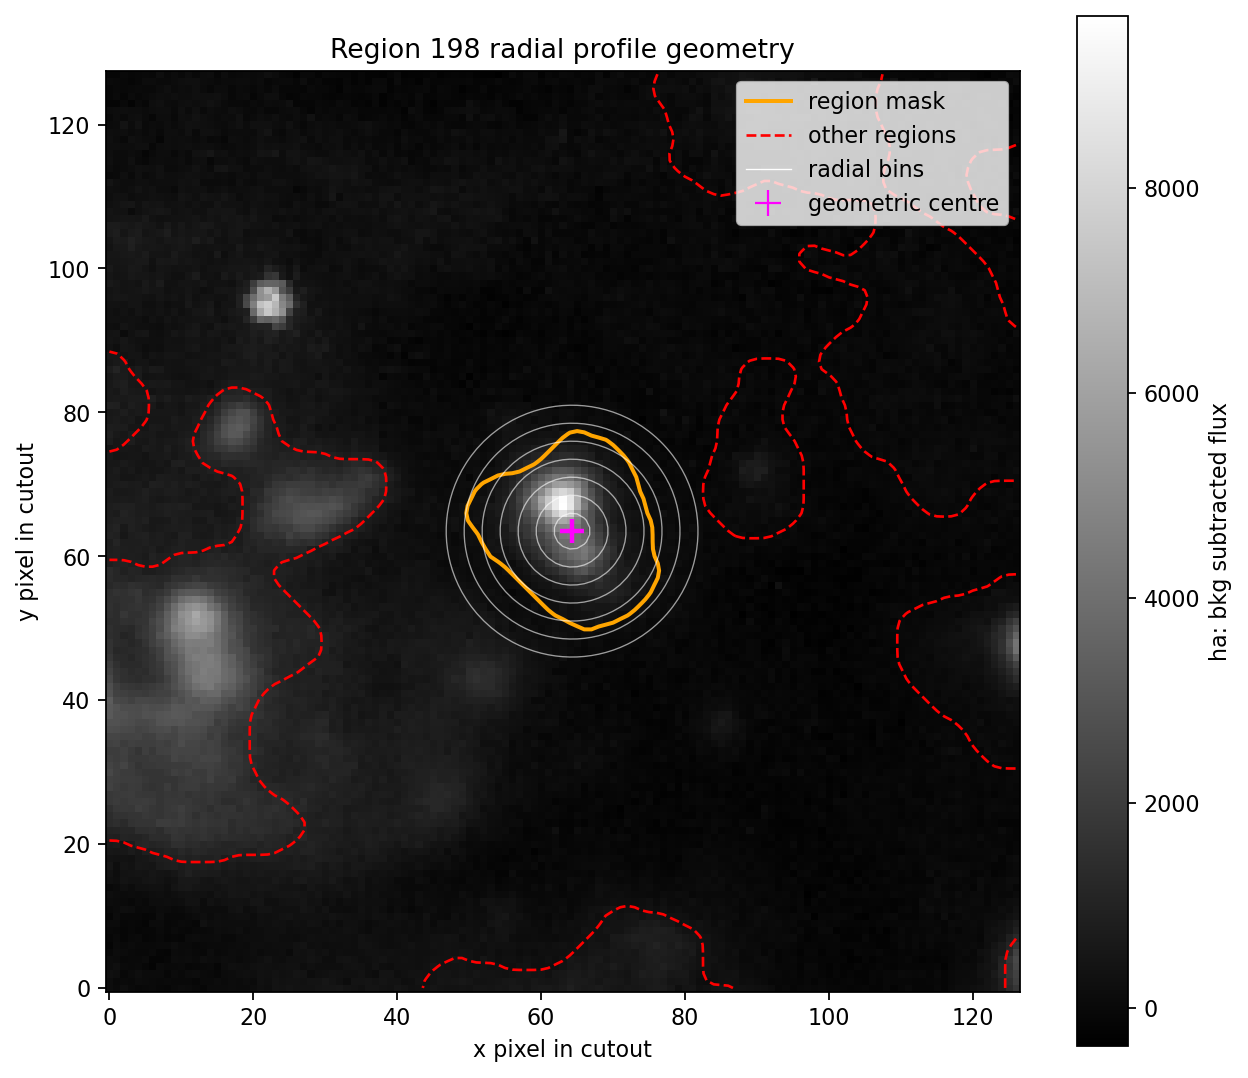

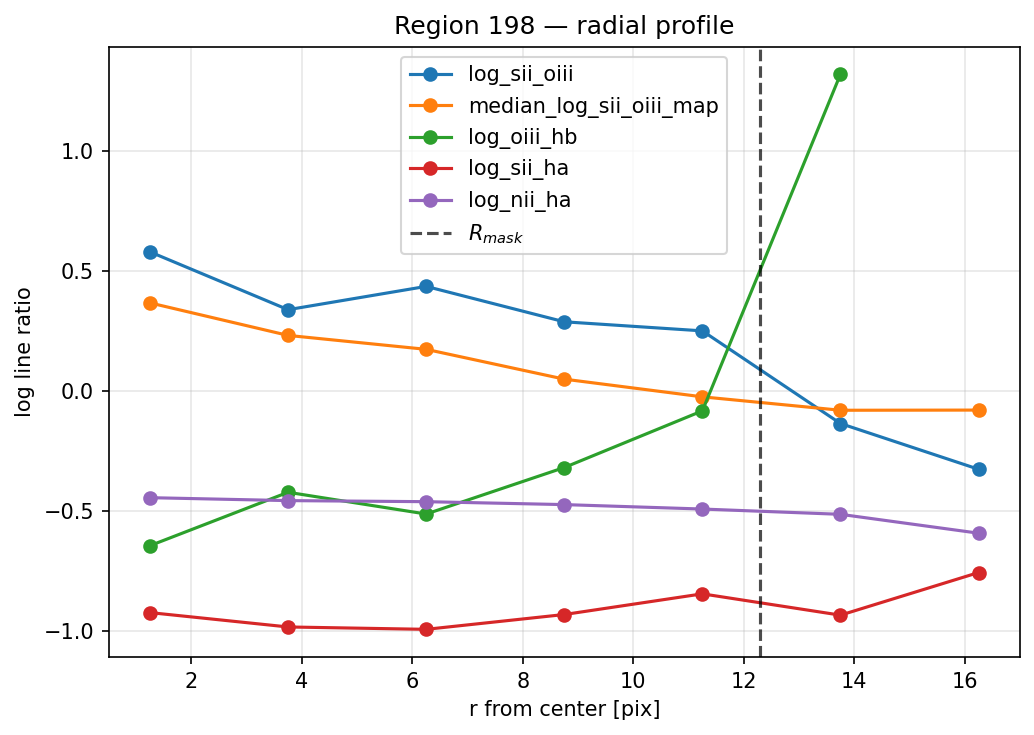

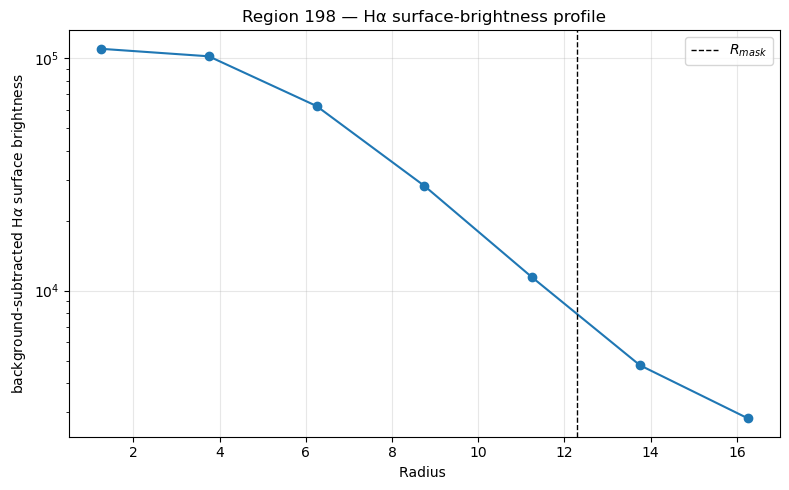

,region_id,core_threshold_log_sii_oiii,rim_threshold_log_sii_oiii,core_area_pix,rim_area_pix,boundary_area_pix,rim_area_fraction,rim_angular_coverage,ipm_class,inner_log_sii_oiii,outer_log_sii_oiii,outer_minus_inner_log_sii_oiii,inner_median_log_sii_oiii_map,outer_median_log_sii_oiii_map,outer_minus_inner_median_log_sii_oiii_map,inner_log_sii_ha,outer_log_sii_ha,outer_minus_inner_log_sii_ha,inner_log_oiii_hb,outer_log_oiii_hb,outer_minus_inner_log_oiii_hb,inner_log_oiii_sii,outer_log_oiii_sii,outer_minus_inner_log_oiii_sii,inner_log_nii_ha,outer_log_nii_ha,outer_minus_inner_log_nii_ha,inner_log_oi_ha,outer_log_oi_ha,outer_minus_inner_log_oi_ha
0,198,-0.061217,-0.013019,138,57,280,0.203571,0.291667,optically_thin_like,0.458399,0.056848,-0.401551,0.29858,-0.052889,-0.351469,-0.953427,-0.889772,0.063656,-0.533571,0.617594,1.151164,-0.458399,-0.056848,0.401551,-0.451015,-0.503202,-0.052187,-2.139151,-1.031452,1.107698


In [68]:
# Change this manually.
region_id = test_id

ipm_res = analyze_one_ipm_region(region_id)

#plot_ipm_contours(ipm_res)
plot_radial_profile_geometry(ipm_res, image="ha", show_every=1)
plot_ipm_radial_profile(ipm_res)
plot_ha_surface_brightness_profile(ipm_res)

pd.DataFrame([ipm_res["rim_summary"]])

## 14. Batch analysis over all potential HII regions

This saves:

- `ipm_rim_summary.csv`
- `ipm_radial_profiles.csv`
- `ipm_rim_summary.pkl`
- `ipm_radial_profiles.pkl`

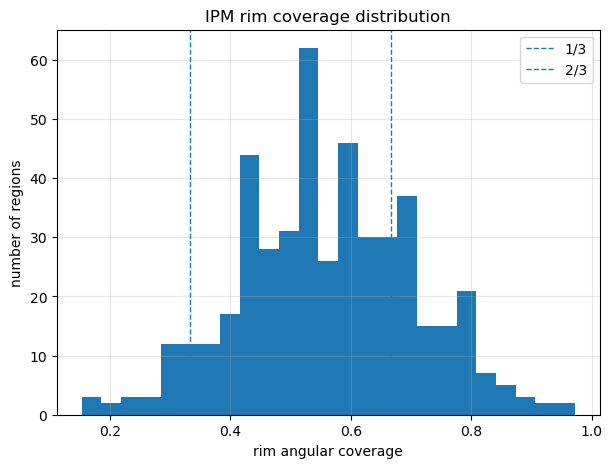

ipm_class
blister_like            318
optically_thick_like    122
optically_thin_like      28
Name: count, dtype: int64

In [19]:
if "error" in summary_df.columns:
    print("Failed regions:", summary_df["error"].notna().sum())

valid_summary = summary_df[summary_df.get("error", pd.Series(index=summary_df.index, dtype=object)).isna()].copy() if "error" in summary_df.columns else summary_df.copy()

plt.figure(figsize=(7, 5))
plt.hist(valid_summary["rim_angular_coverage"].dropna(), bins=25)
plt.axvline(1/3, linestyle="--", linewidth=1, label="1/3")
plt.axvline(2/3, linestyle="--", linewidth=1, label="2/3")
plt.xlabel("rim angular coverage")
plt.ylabel("number of regions")
plt.title("IPM rim coverage distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

valid_summary["ipm_class"].value_counts(dropna=False)

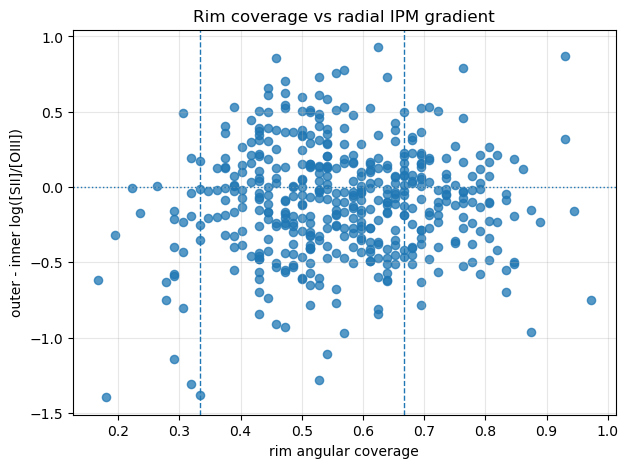

In [20]:
plt.figure(figsize=(7, 5))

xcol = "rim_angular_coverage"
ycol = "outer_minus_inner_log_sii_oiii"

if xcol in valid_summary.columns and ycol in valid_summary.columns:
    plt.scatter(valid_summary[xcol], valid_summary[ycol], s=35, alpha=0.75)
    plt.axvline(1/3, linestyle="--", linewidth=1)
    plt.axvline(2/3, linestyle="--", linewidth=1)
    plt.axhline(0, linestyle=":", linewidth=1)
    plt.xlabel("rim angular coverage")
    plt.ylabel("outer - inner log([SII]/[OIII])")
    plt.title("Rim coverage vs radial IPM gradient")
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("Required columns not available.")

## 16. Inspect interesting cases

In [21]:
def inspect_region_from_results(region_id, results=ipm_results):
    region_id = int(region_id)
    if region_id in results:
        res = results[region_id]
    else:
        res = analyze_one_ipm_region(region_id)

    plot_ipm_contours(res)
    plot_radial_profile_geometry(res, image="ipm", show_every=1)
    plot_ipm_radial_profile(res)
    plot_ha_surface_brightness_profile(res)
    display(pd.DataFrame([res["rim_summary"]]))
    return res


if len(valid_summary):
    thick_like_ids = valid_summary.sort_values("rim_angular_coverage", ascending=False)["region_id"].astype(int).values
    thin_like_ids = valid_summary.sort_values("rim_angular_coverage", ascending=True)["region_id"].astype(int).values

    print("High rim coverage examples:", thick_like_ids[:5])
    print("Low rim coverage examples:", thin_like_ids[:5])

High rim coverage examples: [756 747  62 567 373]
Low rim coverage examples: [390 438 158 301 191]


In [22]:
# Uncomment one of these after running the batch step.
# res = inspect_region_from_results(thick_like_ids[0])
# res = inspect_region_from_results(thin_like_ids[0])

## Notes on interpretation

The automatic labels are not final physical classifications. They are quantitative flags based on the IPM morphology:

- `optically_thick_like`: low-ionisation rim covers most directions around the core.
- `blister_like`: partial low-ionisation rim.
- `optically_thin_like`: weak or absent low-ionisation rim.

For thesis-quality classification, inspect cases where:

- the mask is very irregular,
- nearby regions are close,
- Hα surface brightness is low,
- [OIII] or [SII] has weak S/N,
- the annular profile includes substantial flux outside the original mask.

The most useful columns are:

- `rim_angular_coverage`
- `rim_area_fraction`
- `outer_minus_inner_log_sii_oiii`
- `outer_minus_inner_log_sii_ha`
- `outer_minus_inner_log_oiii_hb`